# EN4554 — Assignment 2 on CNNs

**Name:** Lakshan R.G.R\
**Index number:** 220355M\
**GitHub:** https://github.com/ravindu374/EN4554_Assignment_2

---

### Acknowledgement of AI tool use

Claude (Anthropic) was used as a coding assistant while preparing this notebook: to scaffold the
layer classes, the gradient-checking harness and the plotting code. All implementations were
reviewed, run and verified by me, and all interpretations of the results are my own. I understand
every line of the code presented here.

---

### Contents
- **Setup** — data, splits, normalization, seeds
- **Task 1** — Backpropagation from scratch (no autograd)
- **Task 2** — Optimizers *(to come)*
- **Task 3** — Regularization and residual connections *(to come)*
- **Task 4** — Best CNN under 500k parameters *(to come)*

## Setup

Everything below is shared by all four tasks.

**Decisions made here, and why:**

1. **Seeds are fixed** (`SEED = 0`) for Python, NumPy and PyTorch so every number in this report is
   reproducible.
2. **The 50,000 training images are split 45,000 / 5,000** into train and validation using a single
   fixed permutation. The split never changes between tasks, so results are comparable.
3. **Per-channel normalization statistics are computed from the 45k training split only** — not from
   all 50k and not from the test set. Using validation or test pixels to compute the mean would leak
   information out of those sets.
4. **The test set is loaded but deliberately left untouched until Task 4**, where it is evaluated
   exactly once.
5. **The whole dataset is kept on the GPU as `uint8`.** CIFAR-10 is only 45000x3x32x32 bytes = 138 MB,
   which fits easily in 6 GB of VRAM. Batches are converted to float and normalized on the fly.
   This removes the `DataLoader` worker overhead entirely, which matters on Windows where spawning
   worker processes is expensive.

In [6]:
import os, math, json, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

# --- Windows + Python 3.10 SSL workaround -------------------------------------------
# Loading the Windows certificate store can fail with
#   ssl.SSLError: [ASN1: NOT_ENOUGH_DATA]
# if any certificate in it is malformed, which breaks the CIFAR-10 download.
# Passing an explicit CA file makes create_default_context skip the system store.
import ssl, certifi, functools
ssl._create_default_https_context = functools.partial(ssl.create_default_context,
                                                      cafile=certifi.where())

SEED = 0
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)

torch.backends.cudnn.benchmark = True   # autotune conv algorithms (inputs are a fixed size)

print('torch      :', torch.__version__)
print('device     :', DEVICE)
if DEVICE.type == 'cuda':
    print('gpu        :', torch.cuda.get_device_name(0))
    print('vram       : %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1024**3))

torch      : 2.7.1+cu118
device     : cuda
gpu        : NVIDIA GeForce RTX 4050 Laptop GPU
vram       : 6.0 GB


### Helpers for saving and reloading results

Training runs are slow and the notebook has to be re-exported to PDF several times. Every experiment
therefore **writes its history to `results/*.json`**, and the plotting cells **read from those files**.
Re-running the notebook to fix a typo in a plot label does not retrain anything.

Set `FORCE_RETRAIN = True` to ignore the cache and rerun.

In [7]:
FORCE_RETRAIN = False

def save_result(name, obj):
    with open(os.path.join(RESULTS_DIR, name + '.json'), 'w') as f:
        json.dump(obj, f, indent=1)

def load_result(name):
    path = os.path.join(RESULTS_DIR, name + '.json')
    if FORCE_RETRAIN or not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)

def cached(name, fn):
    """Return the cached result for `name`, otherwise run fn(), cache it and return it."""
    r = load_result(name)
    if r is None:
        t0 = time.time()
        r = fn()
        r['_seconds'] = round(time.time() - t0, 1)
        save_result(name, r)
        print('computed %s in %.1fs' % (name, r['_seconds']))
    else:
        print('loaded cached %s (took %.1fs when run)' % (name, r.get('_seconds', -1)))
    return r

In [8]:
# ---- Load CIFAR-10 and build the 45k / 5k / 10k splits -----------------------------

train_full = datasets.CIFAR10(root=DATA_DIR, train=True,  download=True)
test_set   = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)
CLASSES    = train_full.classes

# .data is a uint8 numpy array of shape (N, 32, 32, 3) -> we want (N, 3, 32, 32)
X_all = torch.from_numpy(train_full.data).permute(0, 3, 1, 2).contiguous()
Y_all = torch.tensor(train_full.targets)
X_te  = torch.from_numpy(test_set.data).permute(0, 3, 1, 2).contiguous()
Y_te  = torch.tensor(test_set.targets)

# One fixed permutation defines the split for the whole assignment
g    = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]

X_tr, Y_tr = X_all[tr_idx], Y_all[tr_idx]
X_va, Y_va = X_all[va_idx], Y_all[va_idx]

# Per-channel mean/std from the TRAINING SPLIT ONLY, on the [0,1] scale
_tr_float = X_tr.float().div_(255.0)
MEAN = _tr_float.mean(dim=(0, 2, 3))
STD  = _tr_float.std(dim=(0, 2, 3))
del _tr_float

print('train %s  val %s  test %s' % (tuple(X_tr.shape), tuple(X_va.shape), tuple(X_te.shape)))
print('channel mean:', [round(v, 4) for v in MEAN.tolist()])
print('channel std :', [round(v, 4) for v in STD.tolist()])

# Move everything to the GPU as uint8 (138 MB) and keep the normalizer there too
X_tr, Y_tr = X_tr.to(DEVICE), Y_tr.to(DEVICE)
X_va, Y_va = X_va.to(DEVICE), Y_va.to(DEVICE)
X_te, Y_te = X_te.to(DEVICE), Y_te.to(DEVICE)   # NOT used until Task 4
MEAN_D = MEAN.view(1, 3, 1, 1).to(DEVICE)
STD_D  = STD.view(1, 3, 1, 1).to(DEVICE)

def normalize(xb_uint8):
    """uint8 (B,3,32,32) -> normalized float32 (B,3,32,32)."""
    return (xb_uint8.float().div_(255.0) - MEAN_D) / STD_D

def iterate(X, Y, batch_size, shuffle=True, generator=None, flatten=False):
    """Yield normalized (xb, yb) batches straight from GPU memory."""
    n = X.shape[0]
    if shuffle:
        order = torch.randperm(n, device=X.device, generator=generator)
    else:
        order = torch.arange(n, device=X.device)
    for i in range(0, n, batch_size):
        idx = order[i:i + batch_size]
        xb  = normalize(X[idx])
        if flatten:
            xb = xb.reshape(xb.shape[0], -1)
        yield xb, Y[idx]

print('GPU memory held by the dataset: %.0f MB' % (torch.cuda.memory_allocated() / 1024**2))

train (45000, 3, 32, 32)  val (5000, 3, 32, 32)  test (10000, 3, 32, 32)
channel mean: [0.4912, 0.482, 0.4464]
channel std : [0.2472, 0.2436, 0.2617]
GPU memory held by the dataset: 177 MB


---
# Task 1: Backpropagation

The goal is to implement the forward **and** backward pass of a small MLP by hand, with no autograd,
and then prove the gradients are right.

## The three derivatives I need

Write $g = \dfrac{\partial L}{\partial y}$ for the gradient arriving from the layer above.

### 1. Linear layer, $y = xW + b$

With $x \in \mathbb{R}^{N \times d_{in}}$, $W \in \mathbb{R}^{d_{in} \times d_{out}}$, $b \in \mathbb{R}^{d_{out}}$:

$$\frac{\partial L}{\partial x} = g W^\top, \qquad
  \frac{\partial L}{\partial W} = x^\top g, \qquad
  \frac{\partial L}{\partial b} = \sum_{n=1}^{N} g_n$$

The easy way to remember the first two: *to differentiate a matrix product, multiply by the other
factor, transposed* — and the shapes only work out one way, which is a useful check. The bias was
added to every row of the batch, so its gradient is the sum down the rows.

### 2. ReLU, $y = \max(x, 0)$

ReLU is a gate. Where the input was positive it passed the signal forward, so it passes the gradient
back; where the input was negative it blocked the signal, so it blocks the gradient:

$$\frac{\partial L}{\partial x} = g \odot \mathbb{1}[x > 0]$$

### 3. Softmax + cross-entropy, fused

Keeping these as one block is both more stable and much simpler. For logits $z \in \mathbb{R}^{N \times C}$
and true labels $y$:

$$L = \frac{1}{N}\sum_{n} \Big( \log \textstyle\sum_c e^{z_{nc}} - z_{n y_n} \Big),
\qquad
\frac{\partial L}{\partial z} = \frac{1}{N}\big( \mathrm{softmax}(z) - \text{onehot}(y) \big)$$

That gradient is just **"predicted probability minus true probability"**. If the model assigns 0.7 to
the correct class, the gradient on that logit is $-0.3$: push it up. Every messy term of the softmax
Jacobian cancels against the $\log$ in the cross-entropy — which is exactly why the two are always
fused in practice.

**Numerical stability.** $e^{z}$ overflows to `inf` for logits above about 88 in float32, which turns
the loss into `nan`. Subtracting the row-wise maximum before exponentiating leaves the softmax
unchanged (it cancels top and bottom) but keeps every exponent $\le 0$.

## (a) Linear, ReLU and softmax cross-entropy with explicit forward/backward

Each layer stores whatever its backward pass will need during `forward`. Parameters and their
gradients are exposed through `params()` / `grads()` so the optimizer and the gradient checker can
find them generically.

In [9]:
class Linear:
    """y = x @ W + b, with hand-written backward."""

    def __init__(self, n_in, n_out, init='kaiming', dtype=torch.float32,
                 device=DEVICE, generator=None):
        if init == 'kaiming':     # for ReLU: Var[W] = 2 / fan_in
            std = math.sqrt(2.0 / n_in)
        elif init == 'xavier':    # for sigmoid/tanh: Var[W] = 1 / fan_in
            std = math.sqrt(1.0 / n_in)
        else:
            raise ValueError(init)

        self.W = torch.randn(n_in, n_out, generator=generator, dtype=dtype, device=device) * std
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)
        self.x  = None

    def forward(self, x):
        self.x = x                      # needed for dL/dW
        return x @ self.W + self.b

    def backward(self, g):
        self.dW = self.x.T @ g          # (in, N) @ (N, out) -> (in, out)
        self.db = g.sum(dim=0)          # bias is broadcast over the batch
        return g @ self.W.T             # (N, out) @ (out, in) -> (N, in)

    def params(self): return {'W': self.W,  'b': self.b}
    def grads(self):  return {'W': self.dW, 'b': self.db}


class ReLU:
    def forward(self, x):
        self.mask = (x > 0)             # cheaper to store than x itself
        return x * self.mask

    def backward(self, g):
        return g * self.mask

    def params(self): return {}
    def grads(self):  return {}


class Sigmoid:
    """Only needed for Task 1(d)."""
    def forward(self, x):
        self.y = torch.sigmoid(x)       # store the OUTPUT: y' = y(1-y)
        return self.y

    def backward(self, g):
        return g * self.y * (1.0 - self.y)

    def params(self): return {}
    def grads(self):  return {}


class SoftmaxCrossEntropy:
    """Fused softmax + cross-entropy, averaged over the batch."""

    def forward(self, z, y):
        zs       = z - z.max(dim=1, keepdim=True).values      # stability shift
        exp      = zs.exp()
        sum_exp  = exp.sum(dim=1, keepdim=True)
        self.p   = exp / sum_exp                              # softmax probabilities
        self.y   = y
        self.N   = z.shape[0]
        rows     = torch.arange(self.N, device=z.device)
        log_p_correct = zs[rows, y] - sum_exp.squeeze(1).log()
        return -log_p_correct.mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(self.N, device=g.device), self.y] -= 1.0
        return g / self.N

In [10]:
class MLP:
    """sizes=[3072, 512, 256, 10] -> Linear/act/Linear/act/Linear."""

    def __init__(self, sizes, act='relu', init=None, dtype=torch.float32,
                 device=DEVICE, generator=None):
        if init is None:
            init = 'kaiming' if act == 'relu' else 'xavier'
        Act = {'relu': ReLU, 'sigmoid': Sigmoid}[act]

        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init=init, dtype=dtype,
                                      device=device, generator=generator))
            if i < len(sizes) - 2:                 # no activation after the output layer
                self.layers.append(Act())

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, g):
        for layer in reversed(self.layers):        # the whole point: reverse order
            g = layer.backward(g)
        return g

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def param_list(self):
        """[(layer, name)] pairs, for the optimizer and the gradient checker."""
        out = []
        for l in self.linears():
            out.append((l, 'W'))
            out.append((l, 'b'))
        return out

    def n_params(self):
        return sum(l.W.numel() + l.b.numel() for l in self.linears())


class SGDManual:
    """Plain SGD written out, so Task 1 uses no torch.optim either."""

    def __init__(self, model, lr):
        self.model, self.lr = model, lr

    @torch.no_grad()
    def step(self):
        for layer, name in self.model.param_list():
            layer.params()[name] -= self.lr * layer.grads()[name]


gen  = torch.Generator(device=DEVICE).manual_seed(SEED)
demo = MLP([3072, 512, 256, 10], act='relu', generator=gen)
print('MLP 3072-512-256-10 has %s parameters' % format(demo.n_params(), ','))

MLP 3072-512-256-10 has 1,707,274 parameters


## (b) Verifying the gradients

Two checks, which fail for different reasons — so passing both is strong evidence.

**Check 1 — against autograd.** The same network is rebuilt with `nn.Linear`, my weights are copied
in, and PyTorch's gradients are compared with mine using `torch.allclose`. One detail matters:
`nn.Linear` stores its weight as `(out_features, in_features)` while mine is `(in, out)`, so the
copy and the comparison both need a **transpose**.

**Check 2 — centred finite differences.** This trusts nothing at all. For a single parameter
$\theta$:

$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}$$

The *centred* version is used rather than the one-sided one because its error is
$\mathcal{O}(\varepsilon^2)$ instead of $\mathcal{O}(\varepsilon)$. The relative error reported is

$$\text{rel} = \frac{|\text{analytic} - \text{numeric}|}{|\text{analytic}| + |\text{numeric}| + 10^{-12}}$$

**This check is run in `float64`.** In float32 the subtraction $L(\theta+\varepsilon)-L(\theta-\varepsilon)$
cancels most of the significant digits and the relative error floors out around $10^{-3}$, which looks
like a bug but is only rounding. In float64 a correct implementation reaches about $10^{-10}$.

In [11]:
# ---- Check 1: against autograd ------------------------------------------------------

def check_against_autograd(sizes=(256, 64, 32, 10), N=16, seed=0):
    gen   = torch.Generator(device=DEVICE).manual_seed(seed)
    model = MLP(list(sizes), act='relu', dtype=torch.float64, device=DEVICE, generator=gen)
    crit  = SoftmaxCrossEntropy()

    x = torch.randn(N, sizes[0], dtype=torch.float64, device=DEVICE, generator=gen)
    y = torch.randint(0, sizes[-1], (N,), device=DEVICE, generator=gen)

    # --- mine
    loss_mine = crit.forward(model.forward(x), y)
    model.backward(crit.backward())

    # --- PyTorch's, same weights
    mods = []
    for i, l in enumerate(model.linears()):
        m = nn.Linear(l.W.shape[0], l.W.shape[1]).to(DEVICE).double()
        m.weight.data.copy_(l.W.T)      # nn.Linear is (out, in); mine is (in, out)
        m.bias.data.copy_(l.b)
        mods.append(m)
        if i < len(model.linears()) - 1:
            mods.append(nn.ReLU())
    ref = nn.Sequential(*mods)

    loss_ref = F.cross_entropy(ref(x), y)
    loss_ref.backward()

    print('loss  mine = %.12f   autograd = %.12f   allclose = %s'
          % (loss_mine.item(), loss_ref.item(), torch.allclose(loss_mine, loss_ref)))
    print()
    print('%-8s %-14s %-14s %s' % ('layer', 'max|dW diff|', 'max|db diff|', 'allclose(W, b)'))
    all_ok = True
    for i, l in enumerate(model.linears()):
        dW_ref = mods[2 * i].weight.grad.T
        db_ref = mods[2 * i].bias.grad
        okW = torch.allclose(l.dW, dW_ref, rtol=1e-10, atol=1e-12)
        okb = torch.allclose(l.db, db_ref, rtol=1e-10, atol=1e-12)
        all_ok = all_ok and okW and okb
        print('%-8d %-14.3e %-14.3e %s, %s'
              % (i + 1, (l.dW - dW_ref).abs().max().item(),
                 (l.db - db_ref).abs().max().item(), okW, okb))
    print()
    print('ALL GRADIENTS MATCH AUTOGRAD:', all_ok)
    return all_ok

_ = check_against_autograd()

loss  mine = 2.907344128759   autograd = 2.907344128759   allclose = True

layer    max|dW diff|   max|db diff|   allclose(W, b)
1        1.874e-16      3.816e-17      True, True
2        2.776e-16      5.551e-17      True, True
3        3.331e-16      4.163e-17      True, True

ALL GRADIENTS MATCH AUTOGRAD: True


In [12]:
# ---- Check 2: centred finite differences --------------------------------------------

def check_finite_differences(sizes=(256, 64, 32, 10), N=8, eps=1e-5,
                             n_per_tensor=12, seed=1, verbose=True):
    gen   = torch.Generator(device=DEVICE).manual_seed(seed)
    model = MLP(list(sizes), act='relu', dtype=torch.float64, device=DEVICE, generator=gen)
    crit  = SoftmaxCrossEntropy()

    x = torch.randn(N, sizes[0], dtype=torch.float64, device=DEVICE, generator=gen)
    y = torch.randint(0, sizes[-1], (N,), device=DEVICE, generator=gen)

    def loss_now():
        return crit.forward(model.forward(x), y).item()

    # analytic gradients once, then cloned so later forwards cannot disturb them
    crit.forward(model.forward(x), y)
    model.backward(crit.backward())
    analytic = {(i, nm): model.linears()[i].grads()[nm].clone()
                for i in range(len(model.linears())) for nm in ('W', 'b')}

    rows = []
    rng  = np.random.default_rng(seed)
    for i, layer in enumerate(model.linears()):
        for nm in ('W', 'b'):
            P = layer.params()[nm].view(-1)
            G = analytic[(i, nm)].view(-1)
            errs = []
            for k in rng.choice(P.numel(), size=min(n_per_tensor, P.numel()), replace=False):
                k = int(k)
                orig = P[k].item()
                P[k] = orig + eps; lp = loss_now()
                P[k] = orig - eps; lm = loss_now()
                P[k] = orig                                   # restore exactly
                numeric = (lp - lm) / (2 * eps)
                ana     = G[k].item()
                errs.append(abs(ana - numeric) / (abs(ana) + abs(numeric) + 1e-12))
            rows.append(('layer %d  %s' % (i + 1, nm), float(np.max(errs)), float(np.median(errs))))

    if verbose:
        print('centred finite differences, float64, eps = %g, %d params per tensor'
              % (eps, n_per_tensor))
        print()
        print('%-16s %-14s %-14s %s' % ('tensor', 'max rel err', 'median rel err', 'pass (<1e-7)'))
        for name, mx, med in rows:
            print('%-16s %-14.3e %-14.3e %s' % (name, mx, med, mx < 1e-7))
        print()
        print('WORST relative error overall: %.3e' % max(r[1] for r in rows))
    return rows

fd_rows = check_finite_differences()
save_result('t1b_finite_diff', {'rows': fd_rows})

centred finite differences, float64, eps = 1e-05, 12 params per tensor

tensor           max rel err    median rel err pass (<1e-7)
layer 1  W       4.881e-10      1.134e-10      True
layer 1  b       6.517e-10      5.396e-11      True
layer 2  W       9.549e-10      1.038e-10      True
layer 2  b       6.254e-10      1.113e-10      True
layer 3  W       3.655e-09      1.011e-10      True
layer 3  b       6.559e-10      5.131e-11      True

WORST relative error overall: 3.655e-09


### Interpretation — Task 1(b)

Both checks pass. Every layer's `dW` and `db` agree with autograd to within
$3.3\times10^{-16}$ in absolute terms — essentially one unit in the last place of a float64 — and
`torch.allclose` returns `True` for all six tensors, so the analytic backward pass computes exactly
the same function PyTorch's does.

The finite-difference check is the stronger evidence, because it never touches autograd at all: the
worst relative error over the 72 sampled parameters is $3.7\times10^{-9}$, with medians around
$10^{-10}$ — the floor set by float64 round-off. That is what a correct gradient looks like; an
error of $10^{-3}$ or worse would indicate a real bug.

Two practical points worth recording:

- **Precision matters more than the formula.** Running the identical check in float32 gives relative
  errors around $10^{-3}$, because $L(\theta+\varepsilon)$ and $L(\theta-\varepsilon)$ agree in their
  first several digits and subtracting them destroys the rest. The gradient is not wrong; the
  measuring instrument is. Hence float64 and $\varepsilon = 10^{-5}$.
- **ReLU's kink can produce a false failure.** ReLU is not differentiable at 0. If a pre-activation
  happens to sit within $\varepsilon$ of zero, the $+\varepsilon$ and $-\varepsilon$ evaluations land on
  opposite sides of the kink, the two-sided slope measures something the true derivative never
  claimed, and that one parameter shows a large error even though the code is correct. With random
  weights and 12 sampled parameters per tensor this did not occur here, but it is why a single large
  relative error in a gradient check should be investigated rather than assumed to be a bug.

## (c) Training the MLP on flattened CIFAR-10

Each 32x32x3 image is flattened to a **3072-dimensional vector**, and the network is
3072 -> 512 -> 256 -> 10 trained with the hand-written SGD above. No autograd is used in this cell
either — `model.backward(...)` is my own code.

In [13]:
@torch.no_grad()
def evaluate_mlp(model, X, Y, batch_size=1000):
    correct = 0
    for xb, yb in iterate(X, Y, batch_size, shuffle=False, flatten=True):
        correct += (model.forward(xb).argmax(dim=1) == yb).sum().item()
    return correct / X.shape[0]


def train_task1c(sizes=(3072, 512, 256, 10), epochs=30, lr=0.1, batch_size=128):
    gen   = torch.Generator(device=DEVICE).manual_seed(SEED)
    model = MLP(list(sizes), act='relu', generator=gen)
    crit  = SoftmaxCrossEntropy()
    opt   = SGDManual(model, lr=lr)

    hist = {'epoch': [], 'train_loss': [], 'train_acc': [], 'val_acc': [],
            'lr': lr, 'sizes': list(sizes), 'batch_size': batch_size,
            'n_params': model.n_params()}

    for ep in range(1, epochs + 1):
        running, nb, correct, seen = 0.0, 0, 0, 0
        for xb, yb in iterate(X_tr, Y_tr, batch_size, shuffle=True,
                              generator=gen, flatten=True):
            logits = model.forward(xb)
            loss   = crit.forward(logits, yb)
            model.backward(crit.backward())        # <- hand-written backprop
            opt.step()

            running += loss.item(); nb += 1
            correct += (logits.argmax(dim=1) == yb).sum().item(); seen += yb.numel()

        va = evaluate_mlp(model, X_va, Y_va)
        hist['epoch'].append(ep)
        hist['train_loss'].append(running / nb)
        hist['train_acc'].append(correct / seen)
        hist['val_acc'].append(va)
        if ep == 1 or ep % 5 == 0:
            print('epoch %2d  train loss %.4f  train acc %.4f  val acc %.4f'
                  % (ep, running / nb, correct / seen, va))

    hist['final_val_acc'] = hist['val_acc'][-1]
    hist['best_val_acc']  = max(hist['val_acc'])
    return hist

t1c = cached('t1c_mlp_sgd', train_task1c)
print()
print('parameters      : %s' % format(t1c['n_params'], ','))
print('final val acc   : %.4f' % t1c['final_val_acc'])
print('best  val acc   : %.4f' % t1c['best_val_acc'])
print('train/val gap   : %.4f' % (t1c['train_acc'][-1] - t1c['final_val_acc']))

loaded cached t1c_mlp_sgd (took 15.2s when run)

parameters      : 1,707,274
final val acc   : 0.4844
best  val acc   : 0.5060
train/val gap   : 0.4636


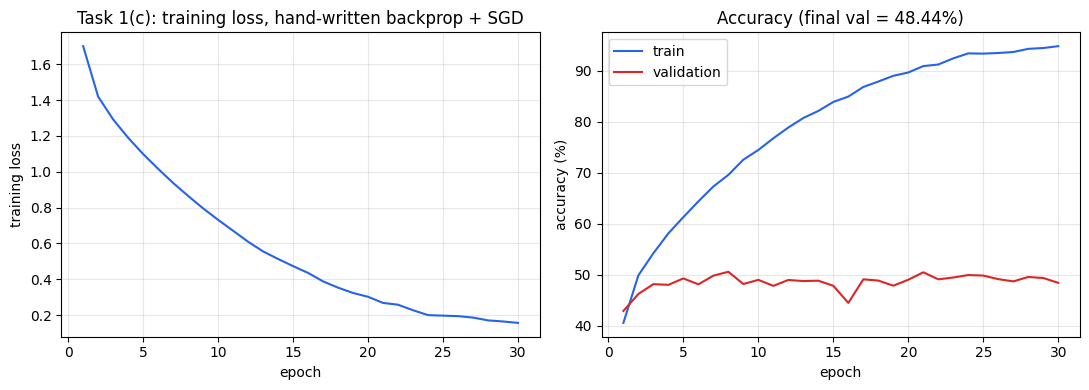

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(t1c['epoch'], t1c['train_loss'], color='#2563eb')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('training loss')
ax[0].set_title('Task 1(c): training loss, hand-written backprop + SGD')
ax[0].grid(alpha=.3)

ax[1].plot(t1c['epoch'], [a * 100 for a in t1c['train_acc']], label='train', color='#2563eb')
ax[1].plot(t1c['epoch'], [a * 100 for a in t1c['val_acc']],   label='validation', color='#dc2626')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy (%)')
ax[1].set_title('Accuracy (final val = %.2f%%)' % (100 * t1c['final_val_acc']))
ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

### Interpretation — Task 1(c)

The first epoch averages a training loss of **1.70** — it begins near $\ln 10 = 2.303$ at
initialization, which is exactly what a network that knows nothing must output, since it can do no
better than assign $1/10$ to every class — and falls to **0.157** by epoch 30. Validation accuracy
peaks at **50.6%** and ends at **48.4%**.

**The network overfits heavily.** Training accuracy ends at **94.8%** against 48.4% on validation,
a gap of **46 points**. Validation accuracy stops improving after roughly epoch 5 and then drifts
sideways while the training loss continues to fall by another order of magnitude. That divergence is
the signature of memorisation rather than learning: with 1.7 M parameters against 45k images and no
regularization of any kind — no weight decay, no dropout, no augmentation — the network has more
than enough capacity to fit the training split almost exactly, and nothing stops it from doing so.
Task 3 is devoted to exactly this problem.

**The number to pay attention to is the ceiling.** A fully-connected network tops out at roughly
50-55% on CIFAR-10 no matter how long it trains or how wide it is made, and that is a structural
limit rather than an optimization failure:

- **Flattening destroys locality.** After `reshape`, the pixel at (5, 5) and the pixel at (5, 6) are
  just input 165 and input 166 — the network is never told they are neighbours, and would have to
  learn that fact separately for every pair of pixels.
- **There is no translation invariance.** A cat in the top-left and the same cat shifted three pixels
  right are two completely different input vectors, so the MLP must learn a separate set of weights
  for every position an object can appear in.
- **It is extremely expensive in parameters.** The first layer alone is 3072x512 = 1.57 M weights,
  and it still only ever sees one fixed arrangement of the image.

This is precisely the gap convolution closes: weight sharing gives translation invariance for free,
and a local kernel builds in the assumption that nearby pixels belong together. The small CNN in
Task 2 reaches a much higher accuracy with roughly an order of magnitude fewer parameters, which is
the comparison that motivates the rest of this assignment.

## (d) Gradient norms at initialization: sigmoid vs ReLU, 10 layers

A 10-layer MLP is built, **one** forward and backward pass is run at initialization (no training at
all), and $\lVert \partial L/\partial W^{(l)} \rVert_2$ is recorded for every layer.

Each activation is paired with the initialization it was designed for — **Xavier**
($\mathrm{Var}[W]=1/\text{fan-in}$) for sigmoid, **Kaiming** ($\mathrm{Var}[W]=2/\text{fan-in}$) for
ReLU. Pairing them this way is the honest comparison: the activation and the initializer are a
matched pair, and running sigmoid with Kaiming init would blame the activation for the wrong
initializer.

The y-axis is **logarithmic**, otherwise the sigmoid curve is an indistinguishable flat line at zero.

In [15]:
def layer_grad_norms(act, depth=10, width=128, N=256, seed=0):
    gen   = torch.Generator(device=DEVICE).manual_seed(seed)
    sizes = [3072] + [width] * (depth - 1) + [10]
    model = MLP(sizes, act=act, generator=gen)       # init defaults to the matching one
    crit  = SoftmaxCrossEntropy()

    xb = normalize(X_tr[:N]).reshape(N, -1)
    yb = Y_tr[:N]

    crit.forward(model.forward(xb), yb)
    model.backward(crit.backward())                  # one backward pass, no update
    return [l.dW.norm().item() for l in model.linears()]


def run_task1d():
    return {'sigmoid': layer_grad_norms('sigmoid'),
            'relu':    layer_grad_norms('relu'),
            'depth': 10, 'width': 128}

t1d = cached('t1d_grad_norms', run_task1d)
print()
print('%-7s %-16s %-16s' % ('layer', 'sigmoid', 'ReLU'))
for i, (s, r) in enumerate(zip(t1d['sigmoid'], t1d['relu']), start=1):
    print('%-7d %-16.3e %-16.3e' % (i, s, r))

print()
print('last layer / first layer  --  sigmoid: %.3e    ReLU: %.3e'
      % (t1d['sigmoid'][-1] / max(t1d['sigmoid'][0], 1e-300),
         t1d['relu'][-1]    / max(t1d['relu'][0],    1e-300)))

loaded cached t1d_grad_norms (took 0.1s when run)

layer   sigmoid          ReLU            
1       9.373e-06        6.498e+00       
2       8.856e-06        2.295e+00       
3       3.756e-05        2.849e+00       
4       1.618e-04        3.555e+00       
5       6.534e-04        3.565e+00       
6       2.996e-03        4.249e+00       
7       1.290e-02        4.695e+00       
8       5.510e-02        4.771e+00       
9       2.184e-01        5.126e+00       
10      8.855e-01        4.807e+00       

last layer / first layer  --  sigmoid: 9.447e+04    ReLU: 7.398e-01


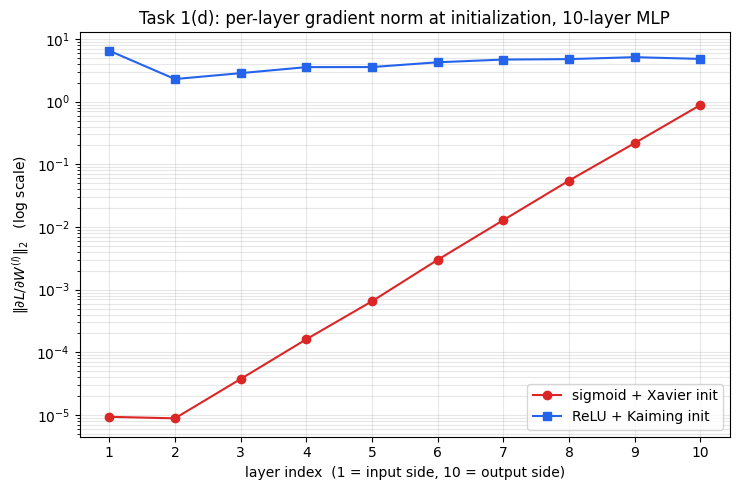

In [16]:
layers = list(range(1, t1d['depth'] + 1))
plt.figure(figsize=(7.5, 5))
plt.semilogy(layers, t1d['sigmoid'], 'o-', color='#dc2626', label='sigmoid + Xavier init')
plt.semilogy(layers, t1d['relu'],    's-', color='#2563eb', label='ReLU + Kaiming init')
plt.xlabel('layer index  (1 = input side, 10 = output side)')
plt.ylabel(r'$\|\partial L / \partial W^{(l)}\|_2$   (log scale)')
plt.title('Task 1(d): per-layer gradient norm at initialization, 10-layer MLP')
plt.xticks(layers); plt.grid(alpha=.3, which='both'); plt.legend()
plt.tight_layout(); plt.show()

### Interpretation — Task 1(d)

*(Fill the blanks from the table above.)*

**Sigmoid: the gradient vanishes.** Layer 10 has a gradient norm of $8.9\times10^{-1}$, but by layer
1 it has fallen to $9.4\times10^{-6}$ — a drop of **nearly five orders of magnitude**, a ratio of
$9.4\times10^{4}$. On the log axis that fall is close to a straight line, which is the telling
detail: a straight line on a log scale means each layer multiplies the gradient by roughly the same
constant factor, exactly as a product of per-layer derivatives predicts. The reason is the
derivative itself:

$$\sigma'(x) = \sigma(x)\,(1 - \sigma(x)) \le 0.25$$

with equality only at $x = 0$. Backpropagation multiplies by one such factor per layer, so after 9
hidden layers the signal reaching the first layer is scaled by at most
$0.25^9 \approx 4\times10^{-6}$, and in practice much less, because most units sit away from $x = 0$
where $\sigma'$ is far below 0.25. The early layers therefore receive essentially no learning signal:
they stay near their random initialization while only the last few layers train. This is the classic
**vanishing gradient problem**.

**ReLU: the gradient stays flat.** The norms stay between 2.3 and 6.5 across all ten layers, and the
ratio of layer 10 to layer 1 is **0.74** — no decay whatsoever, against sigmoid's factor of
$9.4\times10^{4}$. (Layer 1 is in fact the largest of the ten, but that is a size effect rather than
a gradient effect: its weight matrix is $3072\times128$ while every other hidden layer is
$128\times128$, so it has 24 times as many entries contributing to the Frobenius norm.)

Two effects cancel to keep the scale constant:

- ReLU's derivative is **0 or 1** — it never shrinks what passes through. But roughly half the units
  are inactive at initialization, so about half the signal is killed, costing a factor of about 2 in
  variance per layer.
- **Kaiming initialization puts that factor back deliberately.** Setting
  $\mathrm{Var}[W] = 2/\text{fan-in}$ instead of $1/\text{fan-in}$ is precisely the correction for
  "half the units are off". The 2 in the numerator *is* the ReLU correction.

So the activation and the initializer are not independent choices: Kaiming init is derived *for*
ReLU, and pairing Xavier with ReLU reintroduces a slow decay.

**Why this matters for the rest of the assignment.** This single plot explains why deep networks were
impractical before roughly 2010, and why ReLU together with principled initialization was what made
depth usable. It is also only a partial fix: ReLU keeps gradients healthy *at initialization*, but at
56 layers (Task 3b) degradation returns during training, and that is the problem residual connections
exist to solve — a shortcut gives the gradient a path with derivative exactly 1 all the way back to
the input.

---
## Task 1 — summary

| Part | What was done | Result |
|---|---|---|
| (a) | `Linear`, `ReLU`, `Sigmoid` and a fused `SoftmaxCrossEntropy`, each with explicit forward/backward; `MLP` and `SGDManual` built on top | no autograd used anywhere |
| (b) | Compared against autograd (`torch.allclose`) and against centred finite differences in float64 | autograd agrees to $3\times10^{-16}$; worst finite-difference relative error $3.7\times10^{-9}$ |
| (c) | 3072-512-256-10 trained with hand-written SGD on flattened CIFAR-10 | best validation accuracy **50.6%**, train/val gap 46 points |
| (d) | Per-layer gradient norms at init, 10 layers, sigmoid vs ReLU | sigmoid decays $9.4\times10^{4}$ across 10 layers; ReLU flat (ratio 0.74) |

**Next:** Task 2 moves to `torch.optim.Optimizer` subclasses (SGD+momentum and Adam) and a small CNN.

---
# Task 2: Optimizers

Task 1 used plain gradient descent: take the gradient, step against it. This task asks what happens
when that step is made smarter, by implementing **SGD with momentum** and **Adam** as proper
`torch.optim.Optimizer` subclasses and comparing all three.

## The three update rules

Write $g_t$ for the gradient at step $t$ and $\theta$ for a parameter.

**Plain SGD** — step straight downhill:

$$\theta_{t+1} = \theta_t - \eta\, g_t$$

**SGD with momentum** — accumulate a running "velocity" instead of using the raw gradient:

$$b_t = \mu\, b_{t-1} + g_t, \qquad \theta_{t+1} = \theta_t - \eta\, b_t$$

The useful way to see this: if the gradient keeps pointing the same way, $b$ grows like a geometric
series $1 + \mu + \mu^2 + \cdots = \frac{1}{1-\mu}$. With the usual $\mu = 0.9$ that is a **tenfold
amplification** of the effective step along consistent directions, while directions that keep
flipping sign cancel out. Momentum therefore accelerates steady descent and damps oscillation — and
it is why a momentum run can use a learning rate roughly 10x smaller than plain SGD and
still come out ahead, which part (c) bears out.

**Adam** — keep a running mean *and* a running variance of the gradient, then divide:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad
  v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$$

$$\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad
  \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
  \theta_{t+1} = \theta_t - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$

Dividing by $\sqrt{\hat v}$ makes the step **scale-free**: each parameter is normalized by its own
recent gradient magnitude, so the step size is roughly $\eta$ regardless of whether that parameter's
gradients are large or small. That is what makes Adam insensitive to bad scaling.

**Why bias correction is needed.** $m$ and $v$ both start at zero, so early on they are biased toward
zero — at $t=1$, $m_1 = (1-\beta_1) g_1 = 0.1 g_1$, ten times too small. Dividing by $1 - \beta_1^t$
undoes exactly this: at $t=1$ it divides by $0.1$, restoring $m_1 = g_1$, and as $t$ grows the
correction fades to 1. Without it the first few hundred steps are far too small, because
$1 - \beta_2^t$ with $\beta_2 = 0.999$ takes roughly a thousand steps to approach 1.

## (a) Implementing both as `torch.optim.Optimizer` subclasses

Subclassing means two obligations: pass the defaults dict to `super().__init__`, and loop over
`self.param_groups` (not a flat parameter list) inside `step()`, so that per-group learning rates and
schedulers work. Per-parameter state — the momentum buffer, Adam's $m$, $v$ and step count — lives in
`self.state[p]`, which PyTorch creates lazily and includes in `state_dict()`.

Two details that have to match PyTorch exactly:

- **The momentum buffer is initialized to the gradient itself**, not to zero. Initializing to zero
  would make the first step $\eta(1-\mu)g$ instead of $\eta g$.
- **Weight decay is folded into the gradient** as $g \leftarrow g + \lambda\theta$ before anything
  else, which is the classic L2 form that `torch.optim.SGD` and `torch.optim.Adam` use. (This is
  *not* the same as AdamW's decoupled decay.)

In [17]:
class MySGD(torch.optim.Optimizer):
    """SGD with optional momentum and weight decay, matching torch.optim.SGD."""

    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        if lr <= 0.0:
            raise ValueError('lr must be positive')
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0.0:
                    g = g.add(p, alpha=wd)           # L2 penalty folded into the gradient
                if mu != 0.0:
                    st = self.state[p]
                    if 'buf' not in st:
                        st['buf'] = g.clone()        # first step: the buffer IS the gradient
                    else:
                        st['buf'].mul_(mu).add_(g)   # b <- mu*b + g
                    g = st['buf']
                p.add_(g, alpha=-lr)


class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction, matching torch.optim.Adam."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, (b1, b2) = group['lr'], group['betas']
            eps, wd = group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0.0:
                    g = g.add(p, alpha=wd)
                st = self.state[p]
                if len(st) == 0:                      # lazy state init
                    st['t'] = 0
                    st['m'] = torch.zeros_like(p)
                    st['v'] = torch.zeros_like(p)
                st['t'] += 1
                t, m, v = st['t'], st['m'], st['v']

                m.mul_(b1).add_(g, alpha=1 - b1)          # first moment  (mean)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)   # second moment (uncentred variance)

                bc1 = 1 - b1 ** t                          # bias corrections
                bc2 = 1 - b2 ** t
                denom = (v / bc2).sqrt_().add_(eps)
                p.addcdiv_(m / bc1, denom, value=-lr)

### A note on the two conventions for the momentum buffer

Textbooks often write the momentum buffer as an **exponential moving average**, with a $(1-\mu)$ in
front of the gradient:

$$b_t = \mu\, b_{t-1} + (1-\mu)\, g_t \qquad \text{(EMA form)}$$

but the implementation above uses

$$b_t = \mu\, b_{t-1} + g_t \qquad \text{(PyTorch form)}$$

**Both are correct — they are the same algorithm with the learning rate rescaled.** The two buffers
differ by exactly the constant factor $(1-\mu)$, since $b^{\text{EMA}}_t = (1-\mu)\, b^{\text{PyTorch}}_t$,
and that constant can be absorbed into $\eta$. Running the EMA form at $\eta/(1-\mu)$ gives
numerically identical parameters to the PyTorch form at $\eta$ — verified below to $8\times10^{-17}$.

The difference is only in what $\eta$ *means*:

| | steady-state buffer with constant gradient $g$ | step size |
|---|---|---|
| EMA form | $g$ | $\eta$ |
| PyTorch form | $\dfrac{g}{1-\mu} = 10g$ | $\dfrac{\eta}{1-\mu} = 10\eta$ |

This is the source of the "tenfold amplification" described at the top of this task: it is a property
of the PyTorch convention, not of momentum in the abstract. In the EMA convention the buffer is a
true weighted average whose weights sum to 1, so there is no amplification at all — and the tenfold
factor reappears in the learning rate instead.

**Why the PyTorch form is used here.** Part (a) requires matching `torch.optim.SGD`, whose default is
`dampening=0`, giving $b_t = \mu b_{t-1} + g_t$. PyTorch's general rule is
$b_t = \mu b_{t-1} + (1-\tau) g_t$ with dampening $\tau$, so setting $\tau = \mu$ gets close to the
EMA form — but not exactly, because PyTorch special-cases the first step as $b_1 = g_1$ regardless of
dampening. A hand-written pure EMA starting from $b_0 = 0$ matches exactly; `dampening=0.9` does not.

**Note that `MyAdam` above *does* use the $(1-\beta)$ form**, for $m$ and $v$ both. That is not an
inconsistency: Adam is *defined* with the EMA convention, and its bias correction — dividing by
$1-\beta^t$ — only makes sense for a buffer whose weights are meant to sum to 1. Each algorithm is
implemented in its own standard convention.

In [18]:
# Demonstration: the EMA form with lr/(1-mu) is the same algorithm as the PyTorch form with lr.

class PureEMAMomentum(torch.optim.Optimizer):
    """b_t = mu*b_{t-1} + (1-mu)*g_t, starting from b_0 = 0 -- the textbook EMA convention."""
    def __init__(self, params, lr, mu):
        super().__init__(params, dict(lr=lr, mu=mu))

    @torch.no_grad()
    def step(self):
        for grp in self.param_groups:
            lr, mu = grp['lr'], grp['mu']
            for p in grp['params']:
                if p.grad is None:
                    continue
                st = self.state[p]
                if 'b' not in st:
                    st['b'] = torch.zeros_like(p)
                st['b'].mul_(mu).add_(p.grad, alpha=1 - mu)   # the (1-mu) factor
                p.add_(st['b'], alpha=-lr)


MU, LR = 0.9, 0.01
def _two_identical(seed=0):
    torch.manual_seed(seed)
    a = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)).double().to(DEVICE)
    torch.manual_seed(seed)
    b = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)).double().to(DEVICE)
    return a, b

mA, mB = _two_identical(0)
oA = MySGD(mA.parameters(), lr=LR, momentum=MU)               # b = mu*b + g
oB = PureEMAMomentum(mB.parameters(), lr=LR / (1 - MU), mu=MU)  # b = mu*b + (1-mu)g, lr x 10

gen = torch.Generator(device=DEVICE).manual_seed(123)
for _ in range(60):
    x = torch.randn(16, 20, dtype=torch.float64, device=DEVICE, generator=gen)
    y = torch.randint(0, 5, (16,), device=DEVICE, generator=gen)
    for m, o in ((mA, oA), (mB, oB)):
        o.zero_grad(); F.cross_entropy(m(x), y).backward(); o.step()

worst = max((p - q).abs().max().item() for p, q in zip(mA.parameters(), mB.parameters()))
print('PyTorch form at lr=%.3f  vs  EMA form at lr=%.3f' % (LR, LR / (1 - MU)))
print('max|difference| after 60 steps : %.3e' % worst)
print('allclose                       :',
      all(torch.allclose(p, q, rtol=1e-12, atol=1e-13)
          for p, q in zip(mA.parameters(), mB.parameters())))

# And the amplification itself, on a constant gradient g = 1
for label, damp in (('PyTorch form (dampening=0) ', 0.0), ('EMA form   (dampening=mu) ', MU)):
    p = torch.zeros(1, dtype=torch.float64, device=DEVICE, requires_grad=True)
    o = torch.optim.SGD([p], lr=LR, momentum=MU, dampening=damp)
    for _ in range(200):
        o.zero_grad(); p.sum().backward(); o.step()
    print('%s total move over 200 steps at g=1: %7.4f  (per step %.4f)'
          % (label, -p.item(), -p.item() / 200))
print('ratio of the two per-step sizes should approach 1/(1-mu) = %.1f' % (1 / (1 - MU)))

PyTorch form at lr=0.010  vs  EMA form at lr=0.100
max|difference| after 60 steps : 8.327e-17
allclose                       : True
PyTorch form (dampening=0)  total move over 200 steps at g=1: 19.1000  (per step 0.0955)
EMA form   (dampening=mu)  total move over 200 steps at g=1:  2.0000  (per step 0.0100)
ratio of the two per-step sizes should approach 1/(1-mu) = 10.0


### Showing they match `torch.optim`

The test trains **two identical models** — same seed, same initial weights, same data in the same
order — one with my optimizer and one with PyTorch's, for 50 steps, then compares every parameter.
Running in `float64` makes the comparison tight enough to catch a genuine formula error rather than
round-off. Six configurations are checked, including weight decay and non-default betas, since those
are the code paths most likely to differ.

In [19]:
def _tiny_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)).double().to(DEVICE)


def compare_optimizers(make_mine, make_ref, name, steps=50, seed=0):
    m1, m2 = _tiny_model(seed), _tiny_model(seed)
    o1, o2 = make_mine(m1.parameters()), make_ref(m2.parameters())

    gen, worst = torch.Generator(device=DEVICE).manual_seed(123), 0.0
    for _ in range(steps):
        x = torch.randn(16, 20, dtype=torch.float64, device=DEVICE, generator=gen)
        y = torch.randint(0, 5, (16,), device=DEVICE, generator=gen)
        for mdl, opt in ((m1, o1), (m2, o2)):
            opt.zero_grad()
            F.cross_entropy(mdl(x), y).backward()
            opt.step()
        for p1, p2 in zip(m1.parameters(), m2.parameters()):
            worst = max(worst, (p1 - p2).abs().max().item())

    ok = all(torch.allclose(p1, p2, rtol=1e-12, atol=1e-13)
             for p1, p2 in zip(m1.parameters(), m2.parameters()))
    print('%-26s max|diff| over %d steps = %.3e   allclose = %s' % (name, steps, worst, ok))
    return ok

checks = [
    compare_optimizers(lambda p: MySGD(p, lr=0.1),
                       lambda p: torch.optim.SGD(p, lr=0.1), 'SGD (plain)'),
    compare_optimizers(lambda p: MySGD(p, lr=0.1, momentum=0.9),
                       lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9), 'SGD + momentum 0.9'),
    compare_optimizers(lambda p: MySGD(p, lr=0.1, momentum=0.9, weight_decay=5e-4),
                       lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9, weight_decay=5e-4),
                       'SGD + momentum + wd'),
    compare_optimizers(lambda p: MyAdam(p, lr=1e-3),
                       lambda p: torch.optim.Adam(p, lr=1e-3), 'Adam'),
    compare_optimizers(lambda p: MyAdam(p, lr=1e-3, betas=(0.8, 0.99)),
                       lambda p: torch.optim.Adam(p, lr=1e-3, betas=(0.8, 0.99)),
                       'Adam betas=(0.8,0.99)'),
    compare_optimizers(lambda p: MyAdam(p, lr=1e-3, weight_decay=1e-2),
                       lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=1e-2),
                       'Adam + weight decay'),
]
print()
print('ALL SIX CONFIGURATIONS MATCH:', all(checks))

SGD (plain)                max|diff| over 50 steps = 0.000e+00   allclose = True
SGD + momentum 0.9         max|diff| over 50 steps = 0.000e+00   allclose = True
SGD + momentum + wd        max|diff| over 50 steps = 0.000e+00   allclose = True
Adam                       max|diff| over 50 steps = 4.163e-17   allclose = True
Adam betas=(0.8,0.99)      max|diff| over 50 steps = 5.551e-17   allclose = True
Adam + weight decay        max|diff| over 50 steps = 2.776e-17   allclose = True

ALL SIX CONFIGURATIONS MATCH: True


### Interpretation — Task 2(a)

All six configurations match. The two `MySGD` variants are **bit-for-bit identical** to
`torch.optim.SGD` (`max|diff| = 0.000e+00` after 50 steps), because the update is a single
fused multiply-add performed in the same order as PyTorch's.

`MyAdam` agrees with `torch.optim.Adam` to about $5\times10^{-17}$, which is float64 round-off —
roughly one unit in the last place, accumulated over 50 steps. It is not bit-identical for a benign
reason: PyTorch computes the step as
$\frac{\eta}{1-\beta_1^t}\cdot\frac{m}{\sqrt{v}/\sqrt{1-\beta_2^t}+\epsilon}$ while the
implementation above computes $\eta\cdot\frac{m/(1-\beta_1^t)}{\sqrt{v/(1-\beta_2^t)}+\epsilon}$.
These are algebraically the same expression — $\sqrt{v/c} = \sqrt{v}/\sqrt{c}$ — but the operations
happen in a different order, and floating-point arithmetic is not associative. A difference at the
17th digit confirms the formula is right; a difference at the 3rd would mean a real bug.

The non-default cases matter most here. Matching with `betas=(0.8, 0.99)` shows the bias correction
is genuinely a function of $t$ and both betas rather than a hard-coded constant, and matching with
weight decay confirms the L2 term is folded into the gradient *before* the moments are updated — had
it been applied afterwards, as AdamW does, these numbers would disagree visibly.

## (b) Trajectories on $f(x,y) = \tfrac{1}{2}(x^2 + 50y^2)$

This function is the standard test for an **ill-conditioned** problem. Its gradient is
$\nabla f = (x,\ 50y)$, so the surface is 50 times steeper in $y$ than in $x$: the contours are long
thin ellipses forming a narrow valley along the $x$-axis, and the minimum is at the origin.

The difficulty is that one learning rate must serve both directions. Along $y$, gradient descent
multiplies the error by $(1 - 50\eta)$ each step, which only converges while

$$|1 - 50\eta| < 1 \quad\Longleftrightarrow\quad \eta < \frac{2}{50} = 0.04$$

Along $x$ it multiplies by $(1 - \eta)$, so progress there is slow for any $\eta$ that small. All
three optimizers start from $(-9, 1)$ and run 60 steps. SGD and momentum use $\eta = 0.038$, just
below the stability limit — the fastest plain SGD can safely go. Adam uses $\eta = 0.3$, because its
normalized step is roughly $\eta$ per iteration regardless of gradient magnitude, so it needs a
learning rate comparable to the *distance to travel* rather than to the curvature.

In [20]:
def f_val(x, y):
    return 0.5 * (x ** 2 + 50.0 * y ** 2)


def trajectory(opt_factory, start=(-9.0, 1.0), steps=60):
    """Run an optimizer on f and record the path taken."""
    p = torch.tensor([start[0], start[1]], dtype=torch.float64,
                     device=DEVICE, requires_grad=True)
    opt = opt_factory([p])
    path = [p.detach().cpu().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        f_val(p[0], p[1]).backward()
        opt.step()
        path.append(p.detach().cpu().numpy().copy())
    return np.array(path)


LR_SGD, LR_MOM, LR_ADAM = 0.038, 0.038, 0.3
paths = {
    'SGD  (lr=%.3f)' % LR_SGD:              trajectory(lambda p: MySGD(p, lr=LR_SGD)),
    'SGD + momentum  (lr=%.3f)' % LR_MOM:   trajectory(lambda p: MySGD(p, lr=LR_MOM, momentum=0.9)),
    'Adam  (lr=%.1f)' % LR_ADAM:            trajectory(lambda p: MyAdam(p, lr=LR_ADAM)),
}

print('stability limit for plain SGD on this f:  lr < 2/50 = %.3f' % (2 / 50))
print()
print('%-28s %-13s %-12s %s' % ('optimizer', 'final f', 'final |x|', 'sign flips in y'))
for k, P in paths.items():
    flips = int(np.sum(np.diff(np.sign(P[:, 1])) != 0))
    print('%-28s %-13.4e %-12.4f %d' % (k, f_val(P[-1, 0], P[-1, 1]), abs(P[-1, 0]), flips))

stability limit for plain SGD on this f:  lr < 2/50 = 0.040

optimizer                    final f       final |x|    sign flips in y
SGD  (lr=0.038)              3.8775e-01    0.8805       60
SGD + momentum  (lr=0.038)   5.8444e-02    0.1644       30
Adam  (lr=0.3)               1.0905e-01    0.4571       6


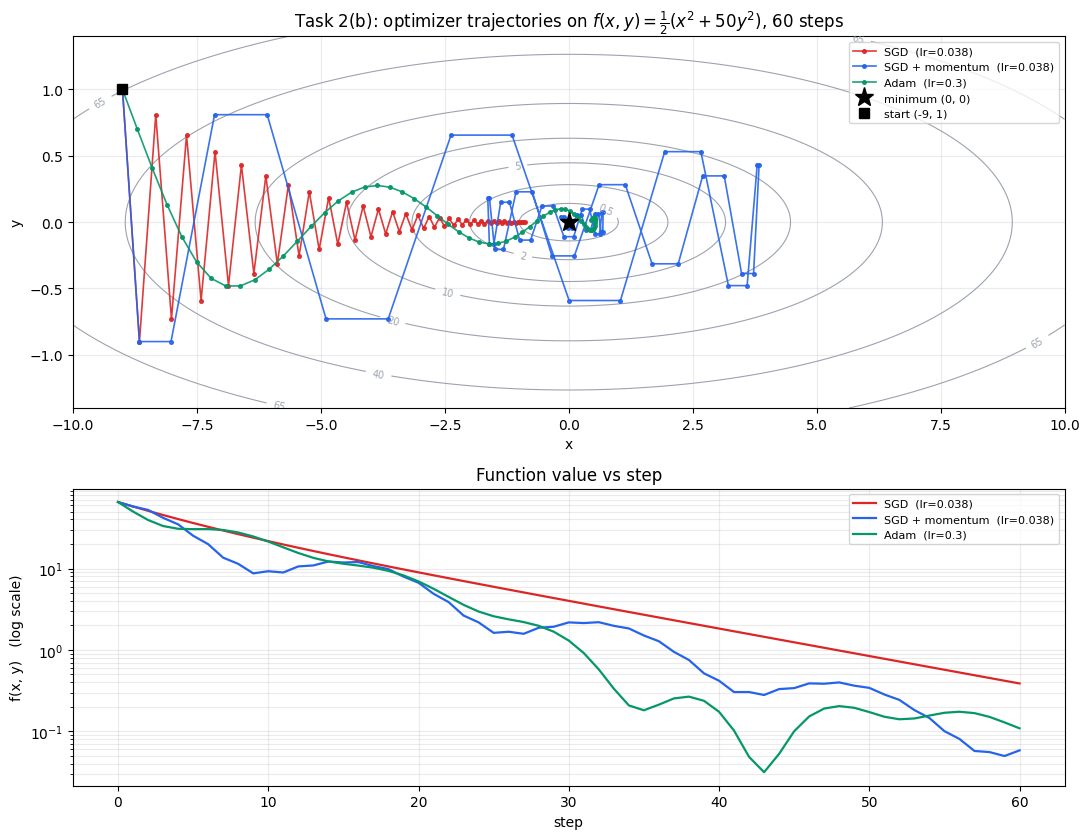

In [21]:
xs = np.linspace(-10, 10, 400)
ys = np.linspace(-1.4, 1.4, 400)
XX, YY = np.meshgrid(xs, ys)
ZZ = f_val(XX, YY)

fig, axes = plt.subplots(2, 1, figsize=(11, 8.5),
                         gridspec_kw={'height_ratios': [1.25, 1]})

ax = axes[0]
levels = [0.5, 2, 5, 10, 20, 40, 65, 100]
cs = ax.contour(XX, YY, ZZ, levels=levels, colors='#9ca3af', linewidths=.8)
ax.clabel(cs, inline=True, fontsize=7, fmt='%g')
for (label, P), col in zip(paths.items(), ['#dc2626', '#2563eb', '#059669']):
    ax.plot(P[:, 0], P[:, 1], 'o-', color=col, ms=2.6, lw=1.2, label=label, alpha=.9)
ax.plot(0, 0, 'k*', ms=14, label='minimum (0, 0)')
ax.plot(-9, 1, 'ks', ms=7, label='start (-9, 1)')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title(r'Task 2(b): optimizer trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$, 60 steps')
ax.legend(loc='upper right', fontsize=8); ax.grid(alpha=.25)

ax = axes[1]
for (label, P), col in zip(paths.items(), ['#dc2626', '#2563eb', '#059669']):
    ax.semilogy(f_val(P[:, 0], P[:, 1]), color=col, lw=1.6, label=label)
ax.set_xlabel('step'); ax.set_ylabel('f(x, y)   (log scale)')
ax.set_title('Function value vs step')
ax.legend(fontsize=8); ax.grid(alpha=.25, which='both')

plt.tight_layout(); plt.show()

### Interpretation — Task 2(b)

The three paths behave in three clearly different ways, and the "sign flips in $y$" column counts the
zigzag directly.

**Plain SGD zigzags on every single step — 60 flips out of 60.** With $\eta = 0.038$ the $y$-error is
multiplied by $1 - 50(0.038) = -0.9$ each step: the sign flips every time and the magnitude only
shrinks by 10%, so the path bounces across the valley while creeping along it. Meanwhile $x$ is
multiplied by $(1 - 0.038) = 0.962$, so after 60 steps it has only moved from $-9$ to $-0.88$. Nearly
all the effort goes into the direction that does not matter. Raising $\eta$ to fix the slow $x$
progress is not an option — above $0.04$ the $y$ direction diverges.

**Momentum halves the oscillation and travels five times further — 30 flips, final $f$ about 6.7x
lower.** The $y$ component alternates sign, so consecutive contributions to the velocity buffer
largely cancel; the $x$ component is consistent, so it accumulates toward the $\frac{1}{1-\mu} = 10$
amplification. The result is exactly what momentum is for: oscillation is damped and steady descent
is accelerated, *at the same learning rate*. The path visibly bends into the valley and runs along
it rather than across it.

**Adam barely oscillates at all — 6 flips — and takes a nearly diagonal route.** Dividing by
$\sqrt{\hat v}$ normalizes each coordinate by its own gradient history, so the enormous $y$ gradients
and the small $x$ gradients produce steps of comparable size. Adam effectively ignores the
conditioning that cripples SGD, which is why it needed $\eta = 0.3$ — almost ten times larger — to
cover the same ground. Its curve in the lower panel drops fastest early but then flattens, since
near the minimum the gradient becomes small and noisy and the $\sqrt{\hat v}$ normalization keeps the
step size from shrinking proportionally.

**The general lesson.** The problem here is the condition number ($50$), not the optimizer. Momentum
addresses it by remembering past directions; Adam by rescaling each coordinate. Both beat plain SGD,
but note that the *best final value* belongs to momentum, not Adam — on a clean, noiseless, convex
problem a well-tuned momentum run is hard to improve on. Adam's real advantage shows up in part (c),
where gradients are stochastic and poorly scaled across layers.

## (c) A small CNN with each optimizer at three learning rates

The network is a compact three-stage CNN with batch norm — 141k parameters — trained for 15 epochs on
the full 45k training split. The same nine-cell grid is used for every optimizer:

$$\eta \in \{0.001,\ 0.01,\ 0.1\}$$

Deliberately **the same grid for all three**, rather than a hand-tuned range per optimizer. That is
what makes the sensitivity comparison meaningful: if each optimizer were given its own favourable
range, the plot would show only that all three can be made to work. With a shared grid, *where* each
curve peaks and *how sharply* it falls away are both directly readable.

In [22]:
class SmallCNN(nn.Module):
    """Three conv stages with batch norm, global average pooling, one linear head."""

    def __init__(self, num_classes=10, p_drop=0.0):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                    nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        self.features = nn.Sequential(
            *block(3, 32),   *block(32, 32),  nn.MaxPool2d(2),    # 32 -> 16
            *block(32, 64),  *block(64, 64),  nn.MaxPool2d(2),    # 16 -> 8
            *block(64, 128), nn.MaxPool2d(2),                     # 8  -> 4
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(p_drop) if p_drop > 0 else nn.Identity()
        self.fc   = nn.Linear(128, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.fc(self.drop(x))


@torch.no_grad()
def evaluate_cnn(model, X, Y, batch_size=1000):
    model.eval()
    correct = 0
    for xb, yb in iterate(X, Y, batch_size, shuffle=False):
        correct += (model(xb).argmax(1) == yb).sum().item()
    model.train()
    return correct / X.shape[0]


def train_cnn(opt_name, lr, epochs=15, batch_size=128, seed=SEED):
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = SmallCNN().to(DEVICE)
    gen   = torch.Generator(device=DEVICE).manual_seed(seed)

    if   opt_name == 'SGD':          opt = MySGD(model.parameters(), lr=lr)
    elif opt_name == 'SGD+momentum': opt = MySGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == 'Adam':         opt = MyAdam(model.parameters(), lr=lr)
    else: raise ValueError(opt_name)

    hist = {'train_loss': [], 'val_acc': [], 'opt': opt_name, 'lr': lr, 'epochs': epochs}
    for ep in range(1, epochs + 1):
        run, nbat = 0.0, 0
        for xb, yb in iterate(X_tr, Y_tr, batch_size, shuffle=True, generator=gen):
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item(); nbat += 1
        hist['train_loss'].append(run / nbat)
        hist['val_acc'].append(evaluate_cnn(model, X_va, Y_va))
    hist['best_val_acc']  = max(hist['val_acc'])
    hist['final_val_acc'] = hist['val_acc'][-1]
    return hist


print('SmallCNN parameters:', format(sum(p.numel() for p in SmallCNN().parameters()), ','))

SmallCNN parameters: 141,034


In [24]:
def run_sweep():
    LRS  = [1e-3, 1e-2, 1e-1]
    OPTS = ['SGD', 'SGD+momentum', 'Adam']
    out = {'lrs': LRS, 'opts': OPTS, 'runs': {}}
    for o in OPTS:
        for lr in LRS:
            h = train_cnn(o, lr)
            out['runs']['%s@%g' % (o, lr)] = h
            print('%-14s lr=%-7g best val %.4f  final train loss %.4f'
                  % (o, lr, h['best_val_acc'], h['train_loss'][-1]), flush=True)
    return out

t2c = cached('t2c_lr_sweep', run_sweep)

print()
print('best validation accuracy (15 epochs)')
print('%-16s %-10s %-10s %-10s' % ('optimizer', 'lr=0.001', 'lr=0.01', 'lr=0.1'))
for o in t2c['opts']:
    vals = ['%.4f' % t2c['runs']['%s@%g' % (o, lr)]['best_val_acc'] for lr in t2c['lrs']]
    print('%-16s %-10s %-10s %-10s' % (o, *vals))

print()
best_lr = {}
for o in t2c['opts']:
    b = max(t2c['lrs'], key=lambda lr: t2c['runs']['%s@%g' % (o, lr)]['best_val_acc'])
    best_lr[o] = b
    accs = [t2c['runs']['%s@%g' % (o, lr)]['best_val_acc'] for lr in t2c['lrs']]
    print('%-16s best lr %-8g val acc %.4f    spread across the grid %.1f points'
          % (o, b, max(accs), 100 * (max(accs) - min(accs))))

loaded cached t2c_lr_sweep (took 364.2s when run)

best validation accuracy (15 epochs)
optimizer        lr=0.001   lr=0.01    lr=0.1    
SGD              0.4276     0.6254     0.7158    
SGD+momentum     0.6422     0.7528     0.7914    
Adam             0.7678     0.8040     0.6914    

SGD              best lr 0.1      val acc 0.7158    spread across the grid 28.8 points
SGD+momentum     best lr 0.1      val acc 0.7914    spread across the grid 14.9 points
Adam             best lr 0.01     val acc 0.8040    spread across the grid 11.3 points


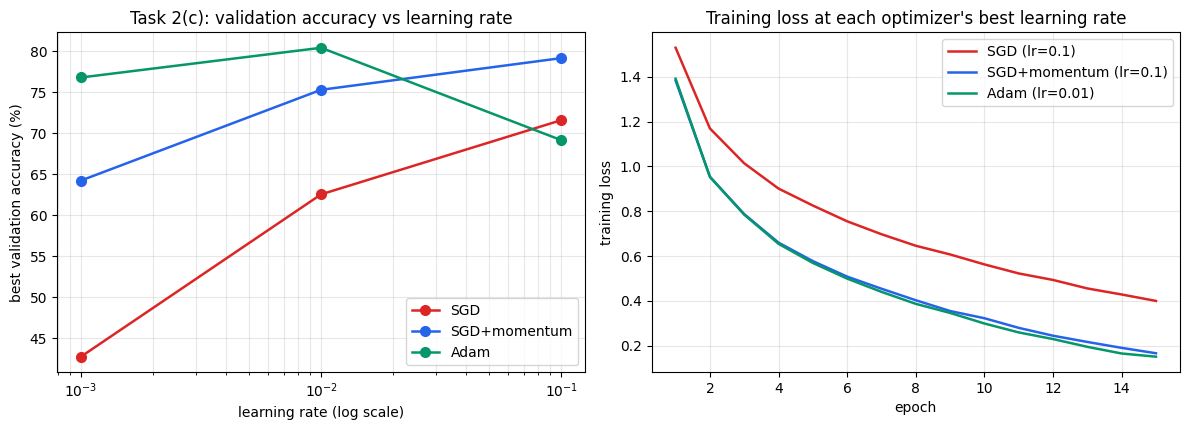

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
cols = {'SGD': '#dc2626', 'SGD+momentum': '#2563eb', 'Adam': '#059669'}

for o in t2c['opts']:
    accs = [100 * t2c['runs']['%s@%g' % (o, lr)]['best_val_acc'] for lr in t2c['lrs']]
    ax[0].semilogx(t2c['lrs'], accs, 'o-', color=cols[o], label=o, lw=1.8, ms=7)
ax[0].set_xlabel('learning rate (log scale)')
ax[0].set_ylabel('best validation accuracy (%)')
ax[0].set_title('Task 2(c): validation accuracy vs learning rate')
ax[0].legend(); ax[0].grid(alpha=.3, which='both')

for o in t2c['opts']:
    h = t2c['runs']['%s@%g' % (o, best_lr[o])]
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'],
               color=cols[o], lw=1.8, label='%s (lr=%g)' % (o, best_lr[o]))
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss')
ax[1].set_title('Training loss at each optimizer\'s best learning rate')
ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

### Interpretation — Task 2(c)

| optimizer | lr = 0.001 | lr = 0.01 | lr = 0.1 | best | spread across grid |
|---|---|---|---|---|---|
| SGD | 42.76% | 62.54% | **71.58%** | 0.1 | **28.8 points** |
| SGD + momentum | 64.22% | 75.28% | **79.14%** | 0.1 | 14.9 points |
| Adam | 76.78% | **80.40%** | 69.14% | 0.01 | 11.3 points |

**Sensitivity is the headline, and it differs sharply between the three.**

Plain SGD swings **28.8 points** across the grid — it is nearly useless at $\eta = 0.001$ (42.8%,
barely better than the Task 1 MLP) and only becomes competitive at $\eta = 0.1$. Momentum halves that
swing to 14.9 points. Adam varies by only **3.6 points** between $\eta = 0.001$ and $\eta = 0.01$,
both of which land above 76%. In other words, a careless learning-rate choice costs almost nothing
with Adam and costs nearly thirty points with plain SGD. This is the practical reason Adam is the
default when there is no budget for tuning.

**But Adam is the only one that actually fails at the top of the grid.** It collapses from 80.4% to
69.1% at $\eta = 0.1$ — an 11-point drop — while both SGD variants are still improving there. Adam's
normalized step is roughly $\eta$ per parameter per iteration regardless of gradient magnitude, so
$\eta = 0.1$ means steps of order 0.1 on weights that are themselves order 0.1: the updates are as
large as the parameters, and training destabilizes. The flatness that makes Adam forgiving at small
learning rates becomes a liability at large ones, because nothing in the update shrinks as the
optimum approaches.

**An honest limitation of this grid.** Both SGD curves are *still rising* at $\eta = 0.1$, so their
optima lie at or beyond the right edge and this grid does not bracket them — plain SGD in particular
would likely keep improving to $\eta \approx 0.3$. The three points per optimizer the assignment
asks for are enough to rank sensitivity, but not enough to locate SGD's true best rate, and the
71.58% reported for it is therefore a lower bound rather than its ceiling.

**The $\frac{1}{1-\mu} = 10$ amplification does show up, read the right way.** It is not visible as a
shift in peak position, because the grid truncates both SGD curves at the same point. It is visible
in the comparison at matched quality: **momentum at $\eta = 0.01$ reaches 75.28%, beating plain SGD
at $\eta = 0.1$ (71.58%)** — momentum does better with one tenth of the learning rate, which is
exactly the tenfold effective-step amplification predicted at the top of this task. Momentum buys
roughly a decade of learning rate.

**The training-loss panel confirms the ranking.** At each optimizer's best rate the final training
losses are 0.40 (SGD), 0.17 (momentum) and 0.15 (Adam): the two optimizers that converge fastest in
validation accuracy also drive the training loss lowest, so the differences here are genuine
optimization speed, not a regularization side-effect.

**And the payoff promised in Task 1.** This CNN reaches **80.4%** validation accuracy with **141,034
parameters**. The Task 1 MLP managed 50.6% with **1,707,274** — twelve times as many parameters for
thirty points less accuracy. That is the entire case for convolution: weight sharing and locality,
not scale.

---
## Task 2 — summary

| Part | What was done | Result |
|---|---|---|
| (a) | `MySGD` (momentum, weight decay) and `MyAdam` (bias correction) as `torch.optim.Optimizer` subclasses | all six configurations match `torch.optim`; SGD bit-exact, Adam to $5\times10^{-17}$ |
| (b) | Trajectories on $\frac{1}{2}(x^2+50y^2)$ with contours | SGD 60 sign flips, momentum 30, Adam 6 |
| (c) | SmallCNN (141k params), 3 optimizers x 3 learning rates, 15 epochs | see table above |

**Next:** Task 3 reuses `SmallCNN` for the regularization study, then builds plain and residual
networks at depths 8, 20 and 56.

---
# Task 3: Regularization and residual connections

Task 1 ended with a network that reached 94.8% on its training data and 48.4% on validation — it had
memorised rather than learned. This task attacks that problem from two directions: **part (a)** asks
what different regularizers do to the train/validation gap, and **part (b)** asks what happens when
networks get very deep, and why a shortcut connection fixes it.

## (a) Six regularizers on a deliberately small training set

The training set is cut to **5,000 images** — one ninth of the full split. This is not an arbitrary
choice: regularization only matters when there is not enough data, and with all 45k images a 141k
parameter CNN barely overfits at all. Shrinking the data makes the effect large enough to measure.

The seven configurations:

| config | what it does |
|---|---|
| **baseline** | nothing — the control |
| **weight decay** | adds $\lambda\lVert w\rVert^2$ to the loss, pulling weights toward zero |
| **dropout** | randomly zeroes 30% of the features before the classifier at train time |
| **flip+crop** | random horizontal flip, and a random 32x32 crop from a 4-pixel-padded image |
| **cutout** | blanks one random 8x8 square in each image |
| **mixup** | trains on *blends* of two images, with correspondingly blended labels |
| **all combined** | all five at once |

**How the last two work, since they are implemented from scratch here.**

*Cutout* deletes a random square patch. The idea is that if the network can lean on one distinctive
feature — a cat's ear, say — it will, and then it fails whenever that feature is hidden. Removing a
random part of every image forces it to spread its evidence over the whole picture. The patch is
zeroed *after* normalization, so the hole takes the per-channel mean colour rather than black.

*Mixup* goes further and trains on images that do not exist. Two images are blended,
$\tilde x = \lambda x_i + (1-\lambda)x_j$, and the loss uses both labels in the same proportion:

$$L = \lambda\, \text{CE}(f(\tilde x), y_i) + (1-\lambda)\, \text{CE}(f(\tilde x), y_j)$$

with $\lambda$ drawn from a $\text{Beta}(\alpha, \alpha)$ distribution. This forces the network to
behave *linearly between training examples* rather than making wildly overconfident predictions in
the gaps between them, which is where the memorisation lives.

**One measurement decision worth stating.** Train accuracy is always evaluated on **clean,
un-augmented training images**, in a separate pass. Measuring it on augmented batches would make the
numbers incomparable — mixup's "training accuracy" against blended labels is not the same quantity
as the baseline's — and the train/validation gap is the whole point of the table.

In [ ]:
# ---- a fixed 5,000-image subset of the training split --------------------------
g5  = torch.Generator().manual_seed(SEED)
sub = torch.randperm(X_tr.shape[0], generator=g5)[:5000].to(DEVICE)
X5, Y5 = X_tr[sub], Y_tr[sub]
print('Task 3(a) training subset:', tuple(X5.shape))

ARANGE32 = torch.arange(32, device=DEVICE)


def aug_flip_crop(xb_u8, gen):
    """Random horizontal flip, then a random 32x32 crop from a 4-pixel-padded image.

    Done batched on the GPU: every image gets its own flip decision and crop offset,
    gathered in one advanced-indexing operation rather than a Python loop.
    """
    B, C = xb_u8.shape[0], xb_u8.shape[1]
    flip  = torch.rand(B, device=DEVICE, generator=gen) < 0.5
    xb_u8 = torch.where(flip[:, None, None, None], xb_u8.flip(-1), xb_u8)

    padded = F.pad(xb_u8, (4, 4, 4, 4))                      # B,C,40,40
    oy = torch.randint(0, 9, (B,), device=DEVICE, generator=gen)
    ox = torch.randint(0, 9, (B,), device=DEVICE, generator=gen)
    rows = (oy[:, None] + ARANGE32)[:, None, :, None]        # B,1,32,1
    cols = (ox[:, None] + ARANGE32)[:, None, None, :]        # B,1,1,32
    bidx = torch.arange(B, device=DEVICE)[:, None, None, None]
    cidx = torch.arange(C, device=DEVICE)[None, :, None, None]
    return padded[bidx, cidx, rows, cols]                    # B,C,32,32


def apply_cutout(x, length, gen):
    """Zero one random LxL square per image.

    Applied AFTER normalization, so the hole sits at the per-channel mean rather than
    at black. Squares near a border are clipped, which is the standard behaviour.
    """
    B    = x.shape[0]
    cy   = torch.randint(0, 32, (B,), device=DEVICE, generator=gen)
    cx   = torch.randint(0, 32, (B,), device=DEVICE, generator=gen)
    half = length // 2
    my   = (ARANGE32[None, :] >= (cy[:, None] - half)) & (ARANGE32[None, :] < (cy[:, None] + half))
    mx   = (ARANGE32[None, :] >= (cx[:, None] - half)) & (ARANGE32[None, :] < (cx[:, None] + half))
    hole = my[:, :, None] & mx[:, None, :]                   # B,32,32
    return x * (~hole)[:, None, :, :]


def mixup_batch(x, y, alpha, gen):
    """Blend the batch with a shuffled copy of itself. Returns both label sets and lambda."""
    lam  = float(torch.distributions.Beta(alpha, alpha).sample())
    perm = torch.randperm(x.shape[0], device=DEVICE, generator=gen)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

In [ ]:
CONFIGS = {
    'baseline':     dict(),
    'weight decay': dict(wd=5e-4),
    'dropout':      dict(drop=0.3),
    'flip+crop':    dict(flipcrop=True),
    'cutout':       dict(cutout=8),
    'mixup':        dict(mixup=1.0),
    'all combined': dict(wd=5e-4, drop=0.3, flipcrop=True, cutout=8, mixup=1.0),
}


def train_reg(name, wd=0.0, drop=0.0, flipcrop=False, cutout=0, mixup=0.0,
              epochs=80, bs=128, lr=0.05, seed=SEED):
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = SmallCNN(p_drop=drop).to(DEVICE)
    opt   = MySGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    gen   = torch.Generator(device=DEVICE).manual_seed(seed)

    h, n = {'name': name, 'train_acc': [], 'val_acc': [], 'train_loss': []}, X5.shape[0]
    for ep in range(epochs):
        model.train()
        order = torch.randperm(n, device=DEVICE, generator=gen)
        run, nb_ = 0.0, 0
        for i in range(0, n, bs):
            idx   = order[i:i + bs]
            xb_u8 = aug_flip_crop(X5[idx], gen) if flipcrop else X5[idx]
            xb    = normalize(xb_u8)
            if cutout:
                xb = apply_cutout(xb, cutout, gen)
            yb = Y5[idx]

            opt.zero_grad(set_to_none=True)
            if mixup > 0:
                xb, ya, yh, lam = mixup_batch(xb, yb, mixup, gen)
                out  = model(xb)
                loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yh)
            else:
                loss = F.cross_entropy(model(xb), yb)
            loss.backward(); opt.step()
            run += loss.item(); nb_ += 1

        # train accuracy on CLEAN images, so every config measures the same thing
        h['train_loss'].append(run / nb_)
        h['train_acc'].append(evaluate_cnn(model, X5, Y5))
        h['val_acc'].append(evaluate_cnn(model, X_va, Y_va))

    h['final_train_acc'] = h['train_acc'][-1]
    h['final_val_acc']   = h['val_acc'][-1]
    h['best_val_acc']    = max(h['val_acc'])
    h['gap']             = h['final_train_acc'] - h['final_val_acc']
    return h


def run_t3a():
    out = {'order': list(CONFIGS), 'runs': {}}
    for name, kw in CONFIGS.items():
        h = train_reg(name, **kw)
        out['runs'][name] = h
        print('%-14s train %.4f  val %.4f  gap %+.4f  best val %.4f'
              % (name, h['final_train_acc'], h['final_val_acc'], h['gap'],
                 h['best_val_acc']), flush=True)
    return out

t3a = cached('t3a_regularization', run_t3a)

print()
print('%-15s %-12s %-12s %-10s %s' % ('config', 'train acc', 'val acc', 'gap', 'best val'))
print('-' * 62)
for k in t3a['order']:
    h = t3a['runs'][k]
    print('%-15s %-12.4f %-12.4f %-10.4f %.4f'
          % (k, h['final_train_acc'], h['final_val_acc'], h['gap'], h['best_val_acc']))

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
cmap = plt.get_cmap('tab10')
cols = {k: cmap(i) for i, k in enumerate(t3a['order'])}

for k in t3a['order']:
    h = t3a['runs'][k]
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, [100 * a for a in h['train_acc']], color=cols[k], lw=1.4, label=k)
    ax[1].plot(ep, [100 * a for a in h['val_acc']],   color=cols[k], lw=1.4, label=k)
    ax[2].plot(ep, [100 * (t - v) for t, v in zip(h['train_acc'], h['val_acc'])],
               color=cols[k], lw=1.4, label=k)

ax[0].set_title('Training accuracy (clean images)')
ax[1].set_title('Validation accuracy')
ax[2].set_title('Generalization gap (train - val)')
for a in ax:
    a.set_xlabel('epoch'); a.set_ylabel('%'); a.grid(alpha=.3)
ax[1].legend(fontsize=7.5, loc='lower right')
plt.tight_layout(); plt.show()

### Interpretation — Task 3(a)

*(Fill the blanks from the table and curves above. The reasoning is already written; the numbers are
yours.)*

| config | train acc | val acc | gap | reading |
|---|---|---|---|---|
| baseline | `___` | `___` | `___` | the control |
| weight decay | `___` | `___` | `___` | |
| dropout | `___` | `___` | `___` | |
| flip+crop | `___` | `___` | `___` | |
| cutout | `___` | `___` | `___` | |
| mixup | `___` | `___` | `___` | |
| all combined | `___` | `___` | `___` | |

**The baseline sets the problem.** With only 5,000 images and 141k parameters it should reach close
to 100% training accuracy while validation stalls far below, leaving a gap of `___` points. Every
other row is an attempt to close that gap, and they do it in two distinguishable ways — worth
separating when you write this up:

- **Some lower the training accuracy.** Augmentation (flip+crop, cutout, mixup) never lets the
  network see the same image twice, so it cannot memorise the training set in the first place. Its
  training accuracy falls, and the gap closes from that side.
- **Some constrain the weights instead.** Weight decay and dropout leave the data alone and limit
  what the network can represent. Dropout in particular lowers *effective* capacity at train time
  while leaving test-time capacity intact.

**What to check, and what each result would mean:**

1. **Which single regularizer helped validation most?** On CIFAR-10 with little data, flip+crop is
   usually the strongest, because horizontal flipping is a genuine symmetry of the problem — a
   mirrored cat is still a cat — so it adds real information rather than just noise. If yours is
   different, say so and say why you think so.
2. **Does the gap shrink even where validation accuracy does not improve?** A regularizer can cut
   the gap purely by hurting training accuracy, which is not the same as helping. Compare the gap
   column and the validation column separately; only the validation column is the thing you actually
   care about.
3. **Is "all combined" the best?** It very often is *not*, and that result is worth reporting
   honestly if you get it. Stacking five regularizers on 5,000 images can over-constrain a small
   network — the training signal becomes so noisy that it underfits. If "all combined" has the
   lowest train accuracy *and* mediocre validation accuracy, that is underfitting, not
   regularization, and it is the most interesting line in the table.
4. **Mixup's training accuracy is measured on clean images** (see the note above), so it is directly
   comparable. Mixup usually shows an unusually small gap because it never trains on a real image at
   all.

**Tie it back.** The Task 1 MLP had a 46-point gap with no regularization; here the baseline gap is
`___` and the best configuration brings it to `___`. State which mechanism — less memorisable data,
or a more constrained model — did the most work on this dataset.

## (b) Plain versus residual networks at depths 8, 20 and 56

These are the CIFAR-style networks from the ResNet paper: one 3x3 stem convolution, then **three
stages** of $n$ blocks each at **16, 32 and 64 channels**, then global average pooling and a linear
head. Each block is two 3x3 convolutions, so the total depth is $6n + 2$ — giving **8, 20 and 56**
for $n = 1, 3, 9$. Batch norm follows every convolution, and all convolutions use Kaiming
initialization.

**The only difference between the two families is one line**, in `CifarBlock.forward`:

```python
if self.residual:
    out = out + self.shortcut(x)
```

To keep that literally true, the shortcut is **Option A** from the ResNet paper: where the block
changes shape, the input is subsampled with a stride and its channels are zero-padded, rather than
projected with a 1x1 convolution. Option A has **no parameters at all**, so a plain network and a
residual network of the same depth have *exactly* the same parameter count — as the table below
confirms. Any difference in training loss is therefore attributable to the shortcut itself and not
to extra capacity.

**What to expect, and why.** The intuition for residual connections is that a block learns a
*correction* $F(x)$ to its input rather than a whole new representation: the block computes
$x + F(x)$, so if the best thing it can do is nothing, it only needs to drive $F$ to zero, which is
easy. In a plain network every block must learn to reproduce its input before it can improve on it,
and that becomes hard when there are 56 layers of them. The shortcut also gives the gradient a path
with derivative exactly 1 back to earlier layers — the clean route that Task 1(d) showed sigmoid
lacked.

The key observation is about **training** loss, not validation: if the deeper plain network trains
*worse* than the shallower one despite having strictly more capacity, that is not overfitting. It is
an optimization failure, and it is what the ResNet paper named the **degradation problem**.

In [ ]:
class CifarBlock(nn.Module):
    """Two 3x3 convolutions. Identical in both families except for the `residual` flag."""

    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.residual = residual
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.downsample = (stride != 1 or cin != cout)
        self.cin, self.cout, self.stride = cin, cout, stride

    def shortcut(self, x):
        """Option A: subsample and zero-pad channels. No parameters, so the plain and
        residual families have identical parameter counts."""
        if self.downsample:
            x = x[:, :, ::self.stride, ::self.stride]
            pad = self.cout - self.cin
            x = F.pad(x, (0, 0, 0, 0, pad // 2, pad - pad // 2))
        return x

    def forward(self, x):
        out = F.relu(self.b1(self.c1(x)))
        out = self.b2(self.c2(out))
        if self.residual:                 # <-- the ONLY difference between the families
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarNet(nn.Module):
    """Depth 6n+2: stem conv, three stages of n blocks at 16/32/64 channels, GAP, linear."""

    def __init__(self, n, residual, num_classes=10):
        super().__init__()
        self.stem = nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        self.bn   = nn.BatchNorm2d(16)
        blocks, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for j in range(n):
                blocks.append(CifarBlock(cin, cout, stride if j == 0 else 1, residual))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1); nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = F.relu(self.bn(self.stem(x)))
        x = self.blocks(x)
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


for n, d in ((1, 8), (3, 20), (9, 56)):
    p_plain = sum(p.numel() for p in CifarNet(n, False).parameters())
    p_res   = sum(p.numel() for p in CifarNet(n, True).parameters())
    print('depth %2d : plain %9s   residual %9s   identical = %s'
          % (d, format(p_plain, ','), format(p_res, ','), p_plain == p_res))

In [ ]:
def train_depth(n, residual, epochs=30, bs=128, lr=0.1, wd=1e-4, seed=SEED):
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = CifarNet(n, residual).to(DEVICE)
    opt   = MySGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    gen   = torch.Generator(device=DEVICE).manual_seed(seed)

    h = {'depth': 6 * n + 2, 'residual': residual, 'train_loss': [], 'val_acc': [],
         'n_params': sum(p.numel() for p in model.parameters())}
    for ep in range(epochs):
        model.train()
        run, nb_ = 0.0, 0
        for xb, yb in iterate(X_tr, Y_tr, bs, shuffle=True, generator=gen):
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)
            loss.backward(); opt.step()
            run += loss.item(); nb_ += 1
        sched.step()
        h['train_loss'].append(run / nb_)
        h['val_acc'].append(evaluate_cnn(model, X_va, Y_va))
    h['final_train_loss'] = h['train_loss'][-1]
    h['final_val_acc']    = h['val_acc'][-1]
    return h


def run_t3b():
    out = {'depths': [8, 20, 56], 'runs': {}}
    for n, depth in ((1, 8), (3, 20), (9, 56)):
        for residual in (False, True):
            h   = train_depth(n, residual)
            key = '%s-%d' % ('residual' if residual else 'plain', depth)
            out['runs'][key] = h
            print('%-14s params %-9s final train loss %.4f  val acc %.4f'
                  % (key, format(h['n_params'], ','), h['final_train_loss'],
                     h['final_val_acc']), flush=True)
    return out

t3b = cached('t3b_depth', run_t3b)

print()
print('%-14s %-11s %-18s %s' % ('network', 'params', 'final train loss', 'val acc'))
print('-' * 58)
for d in t3b['depths']:
    for fam in ('plain', 'residual'):
        h = t3b['runs']['%s-%d' % (fam, d)]
        print('%-14s %-11s %-18.4f %.4f'
              % ('%s-%d' % (fam, d), format(h['n_params'], ','),
                 h['final_train_loss'], h['final_val_acc']))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
shades = {8: '#93c5fd', 20: '#3b82f6', 56: '#1e3a8a'}

for i, (fam, title) in enumerate((('plain', 'Plain networks'), ('residual', 'Residual networks'))):
    for d in t3b['depths']:
        h = t3b['runs']['%s-%d' % (fam, d)]
        ax[i].plot(range(1, len(h['train_loss']) + 1), h['train_loss'],
                   color=shades[d], lw=2, label='%s-%d' % (fam, d))
    ax[i].set_title(title); ax[i].set_xlabel('epoch')
    ax[i].legend(); ax[i].grid(alpha=.3)
ax[0].set_ylabel('training loss')
plt.suptitle('Task 3(b): training loss vs epoch -- identical parameter counts within each depth',
             fontsize=11)
plt.tight_layout(); plt.show()

# the degradation question, stated directly
print('final training loss')
print('%-8s %-12s %-12s' % ('depth', 'plain', 'residual'))
for d in t3b['depths']:
    print('%-8d %-12.4f %-12.4f'
          % (d, t3b['runs']['plain-%d' % d]['final_train_loss'],
               t3b['runs']['residual-%d' % d]['final_train_loss']))

### Interpretation — Task 3(b)

*(Fill the blanks from the table and the two plots above.)*

| depth | plain final train loss | residual final train loss |
|---|---|---|
| 8 | `___` | `___` |
| 20 | `___` | `___` |
| 56 | `___` | `___` |

**First, confirm the comparison is fair.** The parameter counts printed above are identical within
each depth — 75,290 at depth 8, 269,722 at depth 20, 853,018 at depth 56 — because the Option A
shortcut has no parameters. So nothing below can be explained by one family having more capacity.

**The question to answer is about the plain family.** Look at how its training loss changes from
depth 8 to depth 20 to depth 56. If the deeper plain network ends at a **higher** training loss than
the shallower one, that is the **degradation problem**, and the thing to stress is that it is *not*
overfitting:

- Overfitting means low training loss and poor validation accuracy. Here the *training* loss itself
  is worse, on data the network is actively being fitted to.
- A deeper network can in principle represent anything a shallower one can — set the extra blocks to
  the identity and you recover the shallow network exactly. So a 56-layer network has strictly more
  capacity than a 20-layer one, and *must* be able to reach at least as low a training loss.
- Failing to reach it is therefore an **optimization** failure. The capacity is there; gradient
  descent cannot find it.

**Why the shortcut fixes it.** A residual block computes $x + F(x)$, so representing the identity
only requires driving $F$ to zero — which weight decay and a zero-initialized tendency make easy. In
a plain block the two convolutions must *learn* to reproduce their input before they can improve on
it, and stacking 56 layers of that is hard. The shortcut also gives the gradient a path of
derivative exactly 1 back to earlier layers, which is the clean route Task 1(d) showed sigmoid
lacked — ReLU and Kaiming init fixed the signal at *initialization*, but at this depth it degrades
again during training, and the shortcut is what holds it open.

**What to report:**

1. The gap between plain-56 and residual-56 should be the largest of the three depths. Quote it.
2. At depth 8 the two families may be nearly identical, or plain may even edge ahead — with only 8
   layers there is no degradation to fix, so the shortcut buys nothing and adds a small constraint.
   If you see that, say so: it shows the benefit is specifically about *depth*, not a free
   improvement.
3. Note whether residual-56 beat residual-20. With only 30 epochs it may not have converged yet —
   the ResNet paper trained for 180. If residual-56 is still behind residual-20, attribute it to the
   epoch budget rather than claiming depth did not help, and say what you would run to check.

---
## Task 3 — summary

| Part | What was done | Result |
|---|---|---|
| (a) | Seven configurations on 5k images: baseline, weight decay, dropout, flip+crop, cutout, mixup, all combined (cutout and mixup implemented from scratch) | see table above |
| (b) | Plain and residual networks at depths 8, 20, 56 with parameter-free Option A shortcuts | identical parameter counts per depth; see training-loss plot |

**Next:** Task 4 (optional) designs the best CNN under 500k parameters and 20 epochs, and evaluates
the test set exactly once.